# Remote Work and Urban Housing Prices: Final Results
Team 10: Sai Krishna Varshith Danda, Gayathri Kota, Eshitha Chowdary Kaka, Zain Khan

This notebook goes with `report/Team10_Results.pdf`. It runs the follow-up analyses that the methodology document promised and that the
final report adds: the event study on rents and the price-to-rent ratio, the event study without flagged ZIP codes, the work-from-home
coefficient as controls are added (with an exposure-by-distance interaction), and a model of what separates the price-path groups.
The code is in `src/results.py`, which builds on `src/methods.py`. It needs the `src/` folder and `data/clean/`, and takes about a minute.

In [1]:
import sys, warnings
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import viz, methods as M, results as R, viz_results as VR
viz.set_style(); plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
gd, xd = M.load()
cols = ["scope", "n", "2022", "2022 lo", "2022 hi", "2025", "2025 lo", "2025 hi", "2025 minus 2022", "diff lo", "diff hi"]

## 1. The gradient, with and without flagged ZIP codes (SQ1)

The event study gives, for each year, how much more a ZIP code 10 miles farther out gained compared with December 2019, measured within
metro. Intervals are a spatial block bootstrap. We run it on all 1,082 balanced ZIP codes and again without ZIP codes that carry a data-quality flag.

All balanced ZIP codes


,scope,n,2022,2022 lo,2022 hi,2025,2025 lo,2025 hi,2025 minus 2022,diff lo,diff hi
0,All eight (within-metro),1082,0.48,-0.35,1.17,1.15,0.07,1.98,0.67,0.12,1.22
1,Phoenix,147,-0.41,-1.50,0.38,-1.38,-3.79,0.05,-0.96,-2.47,0.05
2,Austin,83,0.57,-2.23,2.55,2.57,-1.76,5.26,2.00,-0.07,3.71
3,Atlanta,202,1.89,-1.13,4.13,4.98,2.40,6.46,3.09,2.10,4.56
4,Dallas,251,0.54,-0.58,1.55,0.46,-0.09,0.97,-0.09,-1.04,0.98
5,Tampa,129,1.51,0.17,2.37,1.73,-0.42,3.23,0.22,-1.25,1.33
6,Charlotte,104,0.25,-1.65,1.58,-0.40,-2.58,1.10,-0.66,-2.01,0.90
7,Nashville,98,-0.51,-1.66,0.17,1.61,-0.16,2.38,2.12,1.26,2.74
8,Las Vegas,68,-0.36,-1.62,0.38,-0.65,-1.36,0.19,-0.29,-0.73,0.89


Without flagged ZIP codes


,scope,n,2022,2022 lo,2022 hi,2025,2025 lo,2025 hi,2025 minus 2022,diff lo,diff hi
0,All eight (within-metro),834,1.25,0.14,2.18,1.81,0.57,2.76,0.56,-0.03,1.22
1,Phoenix,129,0.07,-0.71,0.95,-0.19,-1.62,0.80,-0.27,-1.45,0.70
2,Austin,60,2.11,-1.24,4.69,3.82,-2.08,7.29,1.71,-1.06,4.10
3,Atlanta,150,3.38,-0.77,6.07,6.07,2.44,7.98,2.69,1.38,4.69
4,Dallas,190,1.08,-0.18,2.08,-0.12,-0.86,0.68,-1.20,-2.52,0.30
5,Tampa,124,1.48,0.18,2.48,1.84,-0.48,3.37,0.35,-1.25,1.63
6,Charlotte,69,1.27,-1.58,3.17,1.32,-0.42,2.66,0.05,-0.87,1.78
7,Nashville,58,-0.98,-2.55,0.19,0.88,-1.96,2.06,1.86,0.08,2.71
8,Las Vegas,54,-0.67,-2.99,-0.24,-1.18,-3.07,-0.76,-0.50,-0.91,0.46


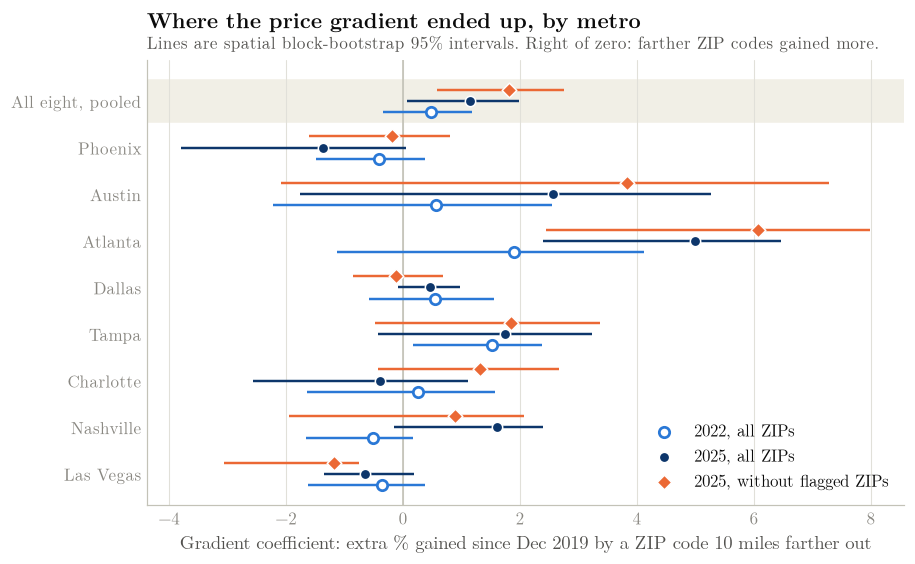

In [2]:
_, full = M.event_study(gd, B=1000)
_, flagfree = R.flag_free_event_study(gd, B=1000)
print("All balanced ZIP codes"); display(full[cols].round(2))
print("Without flagged ZIP codes"); display(flagfree[cols].round(2))
fig = VR.summary_figure(full, flagfree); plt.show()

Atlanta is the clear case and gets stronger without flagged ZIP codes. Phoenix's decline disappears without them, and Las Vegas turns clearly negative.

## 2. Prices against rents: was it mortgage rates?

The same event study on rents, on prices for the same ZIP codes, and on the price-to-rent ratio (prices minus rents in logs, so its coefficient
is the difference between the two gradients). Only ZIP codes with a rent in every December are used, which leaves out most of the outer ring.

,outcome,scope,n,2022,2022 lo,2022 hi,2025,2025 lo,2025 hi,2025 minus 2022,diff lo,diff hi
0,price,All eight (within-metro),403,2.69,0.85,4.34,3.26,1.26,4.58,0.57,-0.55,1.81
9,rent,All eight (within-metro),403,0.89,-0.42,2.07,1.29,-0.30,2.88,0.40,-0.48,1.17
18,price-to-rent ratio,All eight (within-metro),403,1.80,0.91,2.52,1.97,0.42,3.64,0.17,-1.35,1.89


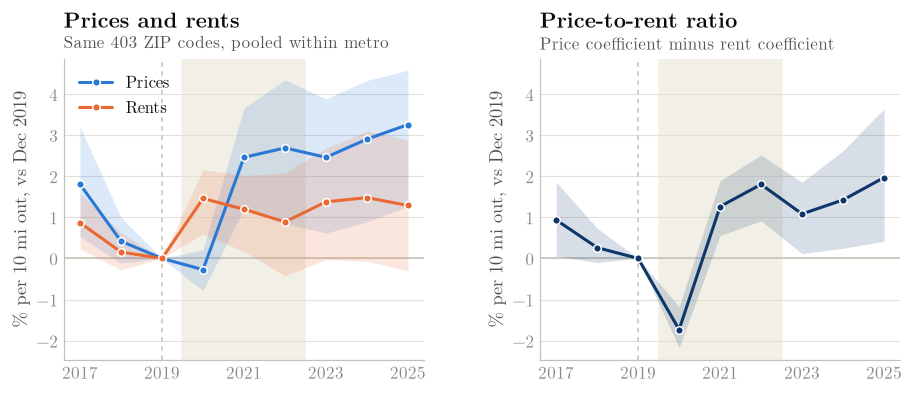

In [3]:
rt, rs = R.rent_event_study(gd, B=1000)
display(rs[rs["scope"].str.startswith("All")][["outcome"] + cols].round(2))
fig = VR.rent_figure(rt); plt.show()

Rents moved outward first (2020), prices overtook them by 2022, and the price-to-rent gap did not close after 2022 (its change includes zero).

## 3. Work-from-home exposure as controls are added (SQ2)

The coefficient on 2015-2019 work-from-home share (per 5 points) for growth in each period, adding controls one group at a time, with four
bootstrap intervals. The last row for each period is the exposure x distance interaction.

,outcome,spec,term,estimate,boot_se,pct_lo,pct_hi,sym_lo,sym_hi,bca_lo,bca_hi
0,2020-22,No controls,wfh5,-0.287,0.184,-0.701,0.002,-0.648,0.075,-0.716,-0.015
1,2020-22,+ distance,wfh5,-0.260,0.167,-0.642,-0.008,-0.587,0.067,-0.651,-0.014
2,2020-22,+ income and home value,wfh5,0.341,0.146,0.117,0.685,0.056,0.627,0.117,0.684
3,2020-22,+ housing type,wfh5,0.293,0.163,0.088,0.692,-0.026,0.613,0.059,0.638
4,2020-22,+ pre-2020 growth,wfh5,0.256,0.151,0.070,0.629,-0.040,0.553,0.044,0.577
5,2020-22,"+ housing type, with WFH x distance",wfh_x_dist,0.042,0.100,-0.137,0.255,-0.155,0.238,-0.148,0.245
6,2023-25,No controls,wfh5,0.402,0.154,0.172,0.765,0.099,0.704,0.127,0.697
7,2023-25,+ distance,wfh5,0.445,0.166,0.212,0.836,0.120,0.770,0.157,0.754
8,2023-25,+ income and home value,wfh5,-0.357,0.145,-0.735,-0.171,-0.641,-0.073,-0.668,-0.122
9,2023-25,+ housing type,wfh5,-0.347,0.131,-0.698,-0.176,-0.605,-0.089,-0.643,-0.127


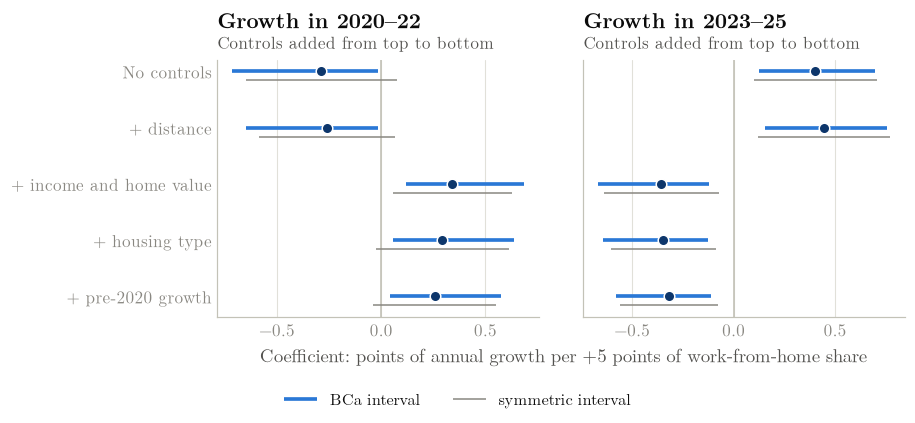

In [4]:
ex = R.exposure_specs(xd, B=1000)
display(ex[["outcome", "spec", "term", "estimate", "boot_se", "pct_lo", "pct_hi", "sym_lo", "sym_hi", "bca_lo", "bca_hi"]].round(3))
fig = VR.exposure_figure(ex); plt.show()

Same specifications without the ZIP codes whose work-from-home estimate is unreliable (margin of error over half the estimate):

In [5]:
exr = R.exposure_specs(xd[~xd["unreliable"]], B=1000)
print(f"{int(exr['n'].iloc[0]):,} ZIP codes")
display(exr[["outcome", "spec", "term", "estimate", "sym_lo", "sym_hi", "bca_lo", "bca_hi"]].round(3))

843 ZIP codes


,outcome,spec,term,estimate,sym_lo,sym_hi,bca_lo,bca_hi
0,2020-22,No controls,wfh5,-0.266,-0.617,0.084,-0.701,-0.009
1,2020-22,+ distance,wfh5,-0.306,-0.665,0.053,-0.769,-0.034
2,2020-22,+ income and home value,wfh5,0.396,0.065,0.727,0.157,0.795
3,2020-22,+ housing type,wfh5,0.335,-0.090,0.759,0.076,0.805
4,2020-22,+ pre-2020 growth,wfh5,0.260,-0.100,0.619,0.037,0.663
5,2020-22,"+ housing type, with WFH x distance",wfh_x_dist,-0.076,-0.307,0.154,-0.315,0.133
6,2023-25,No controls,wfh5,0.542,0.123,0.962,0.199,0.959
7,2023-25,+ distance,wfh5,0.529,0.111,0.948,0.193,0.945
8,2023-25,+ income and home value,wfh5,-0.384,-0.738,-0.030,-0.764,-0.154
9,2023-25,+ housing type,wfh5,-0.363,-0.667,-0.059,-0.693,-0.144


The sign flips when income and home value are added, with or without the unreliable estimates, and the interaction with distance is about zero.
With housing type added, the symmetric interval for 2020-22 includes zero, so that result is not firm.

## 4. What separates the price-path groups? (SQ3)

The four k-means groups from the EDA, predicted by one feature group at a time with a multinomial logit (McFadden pseudo R-squared).

,features,pseudo_r2,accuracy,baseline_accuracy,n,k
0,Metro,0.393,0.787,0.484,1064,4
1,Distance,0.030,0.506,0.484,1064,4
2,Work-from-home share,0.011,0.491,0.484,1064,4
3,Housing type,0.084,0.510,0.484,1064,4
4,"Home value, Dec 2019",0.023,0.475,0.484,1064,4
5,Income,0.004,0.458,0.484,1064,4
6,All of the above,0.505,0.815,0.484,1064,4


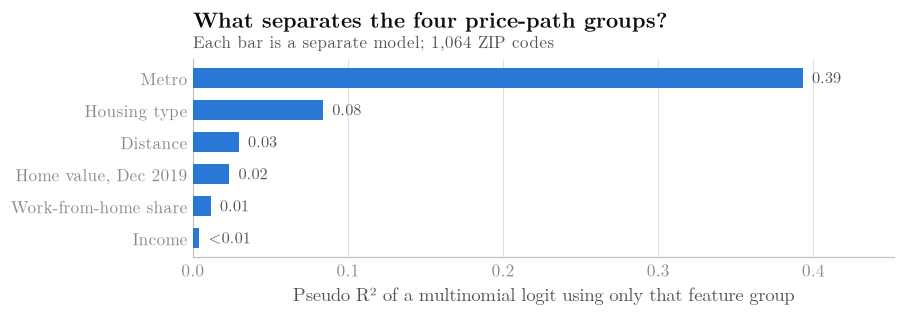

In [6]:
cd = R.cluster_determinants(gd, xd)
display(cd.round(3))
fig = VR.cluster_determinants_figure(cd); plt.show()

Metro explains far more than anything else; housing type separates the groups more than distance, and work-from-home share least of all.